# Delayed labels

Labels rarely come back the moment they are asked for. A sensor reading may be available right
away, while a laboratory assay takes hours, and some samples get lost on the way. With several
outputs, each one can have its own delay. This notebook shows how to evaluate active learning
with delayed labels, and what delays do to query strategies and budgets.

In [1]:
import math
import random

import matplotlib.pyplot as plt
import pandas as pd
from river import multioutput, neighbors

import fishladder as fl

## Declaring delays

`fl.evaluate.prequential` takes a `delay`, counted in instances: a label with a delay of `d` is
learned after the next `d` instances have been predicted. It can be a single value, one value per
output, or a function of the features, the true outputs and the queried output, which can draw
random delays. A delay of `math.inf` means that the label never arrives.

Queries are paid for when they are made, whether or not their labels arrive. Here, `y0` and `y2`
are measured right away, and `y1` comes back from a lab after 50 to 150 instances, except one
sample in 20 that gets lost:

In [2]:
COSTS = {"y0": 1.0, "y1": 1.0, "y2": 1.0}


def knn():
    return neighbors.KNNRegressor(engine=neighbors.LazySearch(window_size=200))


rng = random.Random(0)


def lab_delay(x, y, output):
    if output != "y1":
        return 0
    if rng.random() < 0.05:
        return math.inf
    return rng.randint(50, 150)


log = fl.evaluate.prequential(
    dataset=fl.synth.MultiTarget(n_features=3, correlation=0.3, seed=0).take(2000),
    model=multioutput.PerOutputRegressor(knn()),
    strategy=fl.strategy.RandomPerOutput(p=1.0, seed=0),
    budget=fl.budget.PerOutput(fl.budget.RateBudget(0.6)),
    costs=COSTS,
    delay=lab_delay,
)
df = log.to_frame()
queried = df[df["queried"]].copy()
queried["lost"] = queried["delay"] == math.inf
queried["arrived"] = queried["step"] + queried["delay"] <= df["step"].max()
queried["delay if not lost"] = queried["delay"].where(~queried["lost"])
queried.groupby("output").agg(
    queries=("queried", "size"),
    median_delay=("delay if not lost", "median"),
    lost=("lost", "sum"),
    arrived=("arrived", "sum"),
)

,queries,median_delay,lost,arrived
output,,,,
y0,400,0.0,0,400
y1,400,97.0,22,357
y2,400,0.0,0,400


The log records the delay of each query, in the `delay` column. A label arrives at step
`step + delay`, which tells the labels that were paid for from the ones that the model could
actually use: lost labels and labels still on their way when the stream ended were paid for, but
never learned.

## Waiting for labels with a shared budget

On a stream that does not change, a label is as useful late as it is right away, so a delay
should only hurt at the start. Here, only `y1` is delayed, and all outputs share a single budget
of 0.6 labels per instance.

In [3]:
N = 4000
DELAYS = [0, 200, 500]


def strategies(seed):
    return {
        "random": fl.strategy.RandomPerOutput(p=1.0, seed=seed),
        "expected error": fl.strategy.ExpectedError(knn()),
        "committee": fl.strategy.QueryByCommittee(knn(), seed=seed),
    }


def run(strategy, budget, d, seed, drift=None):
    dataset = fl.synth.MultiTarget(n_features=3, correlation=0.3, drift=drift, seed=seed)
    df = fl.evaluate.prequential(
        dataset.take(N),
        multioutput.PerOutputRegressor(knn()),
        strategy,
        budget,
        COSTS,
        delay={"y0": 0, "y1": d, "y2": 0},
    ).to_frame()
    df["error"] = (df["y_true"] - df["y_pred"]).abs()
    return df


shared = {
    (name, d, seed): run(strategy, fl.budget.RateBudget(0.6), d, seed)
    for seed in range(3)
    for d in DELAYS
    for name, strategy in strategies(seed).items()
}


def share_of_y1(df, start, end):
    queried = df[df["queried"] & (df["step"] >= start) & (df["step"] < end)]
    return (queried["output"] == "y1").mean()


def summary(runs):
    rows = []
    for (name, d, seed), df in runs.items():
        row = {"strategy": name, "delay": d, "seed": seed}
        row["share of labels to y1, first 1000"] = share_of_y1(df, 0, 1000)
        row.update(df.groupby("output")["error"].mean().add_prefix("MAE ").to_dict())
        rows.append(row)
    table = pd.DataFrame(rows).groupby(["strategy", "delay"]).mean().drop(columns="seed")
    return table.round(2)


summary(shared)

share of labels to y1, first 1000  MAE y0  MAE y1  \
strategy       delay                                                      
committee      0                                   0.35    0.25    0.26   
               200                                 0.45    0.27    0.24   
               500                                 0.64    0.30    0.24   
expected error 0                                   0.27    0.26    0.29   
               200                                 0.55    0.34    0.24   
               500                                 0.99    0.43    0.24   
random         0                                   0.33    0.24    0.24   
               200                                 0.33    0.24    0.24   
               500                                 0.33    0.24    0.24   

                      MAE y2  
strategy       delay          
committee      0        0.23  
               200      0.25  
               500      0.29  
expected error 0        0.23  
               200      0.30  
               500      0.41  
random         0        0.21  
               200      0.21  
               500      0.21

The table shows the share of the labels that went to `y1` in the first 1000 instances, and the
error of each output over the whole stream, averaged over three streams. With random querying,
the delay changes nothing: `y1` gets a third of the labels, and its error barely moves.

The uncertainty strategies are another story. While no label of `y1` has arrived, they know
nothing about it, so they give it an infinite utility and the shared budget goes to it, at the
expense of `y0` and `y2`. The longer the delay, the longer this lasts:

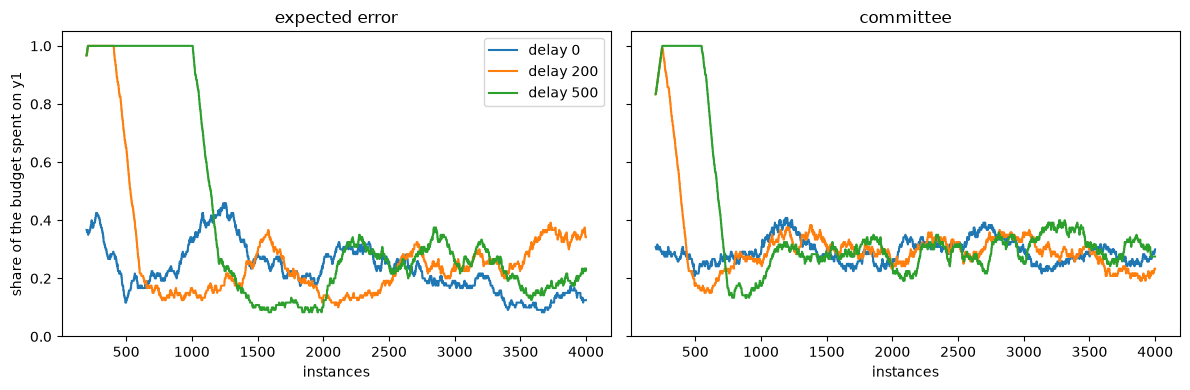

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, name in zip(axes, ["expected error", "committee"]):
    for d in DELAYS:
        df = shared[name, d, 0]
        y1 = df[df["output"] == "y1"].set_index("step")["queried"]
        ax.plot(y1.rolling(200).sum() / (0.6 * 200), label=f"delay {d}")
    ax.set(title=name, xlabel="instances", ylim=(0, 1.05))
axes[0].set_ylabel("share of the budget spent on y1")
axes[0].legend()
fig.tight_layout()

The committee needs `min_labels` labels of an output before it trusts its members, so it waits
for about `d` instances. Expected error waits for about twice as long. It learns the error of the
prediction that each query was made with, and the queries made before the first label arrived
had no prediction to learn an error from. It takes the labels of queries made after that, which
arrive another `d` instances later.

This is the behaviour of the strategies in a delayed setting, not an artefact of the evaluation:
a deployed system would spend its budget the same way while waiting for the lab.

## Per-output budgets

Per-output budgets stop an output from taking the others' budget, so the delay of `y1` no
longer hurts `y0` and `y2`:

In [5]:
per_output = {
    (name, d, seed): run(strategy, fl.budget.PerOutput(fl.budget.RateBudget(0.6)), d, seed)
    for seed in range(3)
    for d in [0, 500]
    for name, strategy in strategies(seed).items()
    if name != "committee"
}
summary(per_output)

share of labels to y1, first 1000  MAE y0  MAE y1  \
strategy       delay                                                      
expected error 0                                   0.33    0.24    0.24   
               500                                 0.33    0.24    0.24   
random         0                                   0.33    0.24    0.24   
               500                                 0.33    0.24    0.24   

                      MAE y2  
strategy       delay          
expected error 0        0.21  
               500      0.21  
random         0        0.21  
               500      0.21

Each output gets a third of the labels whatever the delay, and the errors are the same with and
without it. They are also the same for both strategies since, as in the synthetic streams
notebook, a strategy cannot pick which instances to label with `RateBudget` alone.

## When late labels are stale

Delays matter more when the stream changes: labels that arrive after a drift may describe the
old concept. Here, `y1` drifts after 2000 instances. With per-output budgets and random
querying, we look at how quickly `y1` recovers for different delays.

In [6]:
DRIFT = 2000
drifting = {
    (d, seed): run(
        fl.strategy.RandomPerOutput(p=1.0, seed=seed),
        fl.budget.PerOutput(fl.budget.RateBudget(0.6)),
        d,
        seed,
        drift={"y1": DRIFT},
    )
    for seed in range(3)
    for d in [0, 100, 300]
}

rows = []
for (d, seed), df in drifting.items():
    error = df[df["output"] == "y1"].set_index("step")["error"]
    row = {"delay": d, "seed": seed, "before": error.loc[DRIFT - 500 : DRIFT - 1].mean()}
    for start in range(0, 1000, 200):
        window = error.loc[DRIFT + start : DRIFT + start + 199]
        row[f"{start}-{start + 200}"] = window.mean()
    rows.append(row)
recovery = pd.DataFrame(rows).groupby("delay").mean().drop(columns="seed").round(2)
recovery.columns.name = "instances after the drift"
recovery

instances after the drift,before,0-200,200-400,400-600,600-800,800-1000
delay,,,,,,
0,0.22,0.83,0.68,0.51,0.40,0.29
100,0.22,0.89,0.77,0.56,0.46,0.34
300,0.22,0.91,0.93,0.73,0.59,0.45


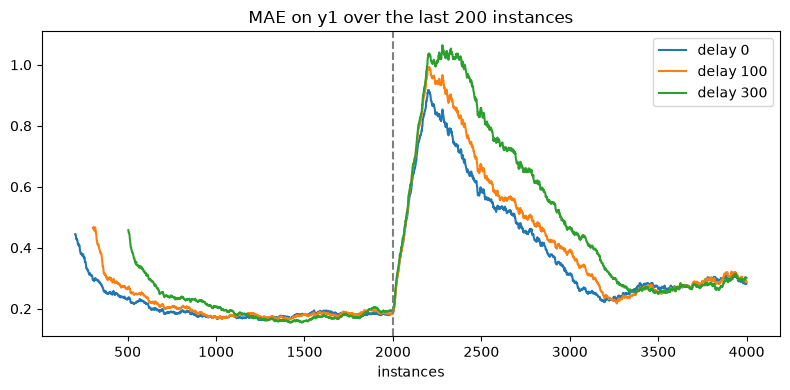

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
for d in [0, 100, 300]:
    df = drifting[d, 0]
    y1 = df[df["output"] == "y1"].set_index("step")["error"]
    ax.plot(y1.rolling(200).mean(), label=f"delay {d}")
ax.axvline(DRIFT, color="grey", linestyle="--")
ax.set(xlabel="instances", title="MAE on y1 over the last 200 instances")
ax.legend()
fig.tight_layout()

In the 500 instances before the drift, the delay makes no difference. After it, the model keeps learning from labels
of the old concept for `d` more instances, so it recovers later, and the error stays higher for
longer the longer the delay.

To sum up: on a stable stream, a delay costs little by itself, but it can make uncertainty
strategies spend a shared budget on the output they are waiting for. After a change, delayed
labels slow down the recovery. Both effects depend on the delay of each output, which is what
the `delay` of `fl.evaluate.prequential` lets you study.